In [2]:
import pandas as pd

In [3]:
import numpy as np

In [4]:
mob_rev = pd.read_csv(r"C:\Users\Nanda\OneDrive\Documents\USL_Project\Dataset\Mobile_Reviews_Sentiment_null.csv",encoding_errors="ignore")

In [5]:
mob_rev

,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,₹27996.73,INR,83.00,2.0,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,R$1754.35,BRL,5.70,4.0,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,₹71755.99,INR,83.00,4.0,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,د.إ2425.65,AED,3.67,3.0,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,R$4515.14,BRL,5.70,3.0,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,Rebecca Pratt,18,Realme,Realme 12 Pro,526.10,A$804.93,AUD,1.53,4.0,...,English,8/17/2023,False,3,3,4,3,5,4,BestBuy
49996,49997,Dr. Tiffany Patterson,28,Samsung,Galaxy Note 20,911.85,A$1395.13,AUD,1.53,3.0,...,English,9/23/2023,False,3,2,4,1,3,2,AliExpress
49997,49998,Alexandra Singh,21,Apple,iPhone SE,1155.32,د.إ4240.02,AED,3.67,NaN,...,English,4/4/2023,True,2,3,4,4,5,4,Amazon
49998,49999,Robert Morris,31,Realme,Realme Narzo 70,459.04,NaN,USD,1.00,3.0,...,English,7/11/2025,True,1,2,2,1,3,6,NaN


In [6]:
duplicates =mob_rev[mob_rev[["customer_name"]].duplicated()]

In [7]:
duplicates.shape

(4089, 22)

In [8]:
mob_rev["price_local"] = (
    mob_rev["price_local"]
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

In [9]:
#mob_rev.drop(columns=["review_id","customer_name"],inplace=True)

In [10]:
numcols = mob_rev.select_dtypes(include='number').columns

In [11]:
catcols = mob_rev.select_dtypes(exclude='number').columns

In [12]:
mob_rev[numcols] = mob_rev[numcols].fillna(mob_rev[numcols].mean())

In [13]:
mob_rev[catcols] = mob_rev[catcols].fillna(mob_rev[catcols].mode().iloc[0])

In [14]:
mob_rev

,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,27996.730000,INR,83.00,2.000000,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,1754.350000,BRL,5.70,4.000000,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,71755.990000,INR,83.00,4.000000,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,2425.650000,AED,3.67,3.000000,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,4515.140000,BRL,5.70,3.000000,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,Rebecca Pratt,18,Realme,Realme 12 Pro,526.10,804.930000,AUD,1.53,4.000000,...,English,8/17/2023,False,3,3,4,3,5,4,BestBuy
49996,49997,Dr. Tiffany Patterson,28,Samsung,Galaxy Note 20,911.85,1395.130000,AUD,1.53,3.000000,...,English,9/23/2023,False,3,2,4,1,3,2,AliExpress
49997,49998,Alexandra Singh,21,Apple,iPhone SE,1155.32,4240.020000,AED,3.67,3.123415,...,English,4/4/2023,True,2,3,4,4,5,4,Amazon
49998,49999,Robert Morris,31,Realme,Realme Narzo 70,459.04,8264.118693,USD,1.00,3.000000,...,English,7/11/2025,True,1,2,2,1,3,6,eBay


In [15]:
USL_Copy = mob_rev.copy()

In [16]:
Kmeansdata = USL_Copy[["age","price_usd","battery_life_rating","camera_rating"]]

In [17]:
from sklearn.preprocessing import StandardScaler

In [18]:
scaling = StandardScaler()

In [19]:

scaleddata = scaling.fit_transform(Kmeansdata)

In [20]:
scaleddata

array([[ 1.67108016, -1.1650794 , -1.2742381 , -1.27706712],
       [-1.35202399, -1.26265874,  0.20915899, -0.53356608],
       [-0.34432261,  0.57707369,  0.20915899,  1.69693702],
       ...,
       [-1.01612353,  1.5379642 , -0.53253956,  0.20993495],
       [ 0.10354468, -0.7628331 , -1.2742381 , -0.53356608],
       [ 1.55911334, -1.02348526,  0.95085754,  1.69693702]],
      shape=(50000, 4))

In [21]:
from sklearn.cluster import KMeans,DBSCAN

In [22]:
Km = KMeans(n_clusters=10,max_iter=300,random_state=42)

In [23]:
newcatdata = Km.fit_predict(scaleddata)

In [24]:
newcatdata

array([6, 0, 8, ..., 2, 9, 1], shape=(50000,), dtype=int32)

In [25]:
Kmeansdata['Group'] = pd.DataFrame(newcatdata)

In [26]:
Kmeansdata.groupby("Group").mean().round(2)

,age,price_usd,battery_life_rating,camera_rating
Group,,,,
0,25.76,565.82,3.50,1.66
1,39.23,616.72,4.37,4.40
2,25.39,1093.46,1.61,1.63
3,23.98,524.36,4.45,4.00
4,24.14,549.27,2.31,3.60
5,39.56,522.19,2.97,3.13
6,38.74,555.18,1.41,1.45
7,40.90,1092.20,2.43,2.38
8,26.29,1104.11,3.86,3.88


In [27]:
len(set(Km.labels_))

10

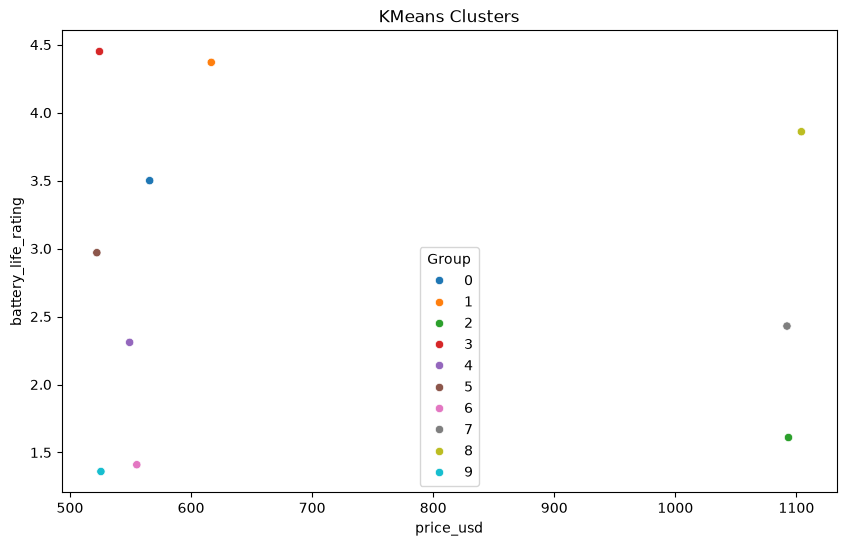

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=Kmeansdata.groupby("Group").mean().round(2),
    x="price_usd",
    y="battery_life_rating",
    hue="Group",
    palette="tab10"
)

plt.title("KMeans Clusters")
plt.show()

In [29]:
from sklearn.metrics import silhouette_score

In [30]:
display(silhouette_score(scaleddata,Km.labels_,sample_size=5000,random_state=42))

0.21055378334125707

In [31]:
display(Km.inertia_)

63208.956970908686

In [32]:
for k in range(2,11):

    km = KMeans(
        n_clusters=k,
        random_state=42
    )

    labels = km.fit_predict(scaleddata)

    score = silhouette_score(
        scaleddata,
        labels,
        sample_size=5000,
        random_state=42
    )

    print(
        f"K={k}, "
        f"Silhouette={score:.3f}"
    )

K=2, Silhouette=0.270
K=3, Silhouette=0.229
K=4, Silhouette=0.234
K=5, Silhouette=0.217
K=6, Silhouette=0.212
K=7, Silhouette=0.215
K=8, Silhouette=0.212
K=9, Silhouette=0.213
K=10, Silhouette=0.211


In [33]:
DBS = DBSCAN(eps=0.75,min_samples=5)

In [34]:
DBSData = DBS.fit_predict(scaleddata)

In [35]:
Kmeansdata['DBS'] = pd.DataFrame(DBSData)

In [36]:
Kmeansdata['DBS'].value_counts()

DBS
 0    49977
-1       23
Name: count, dtype: int64

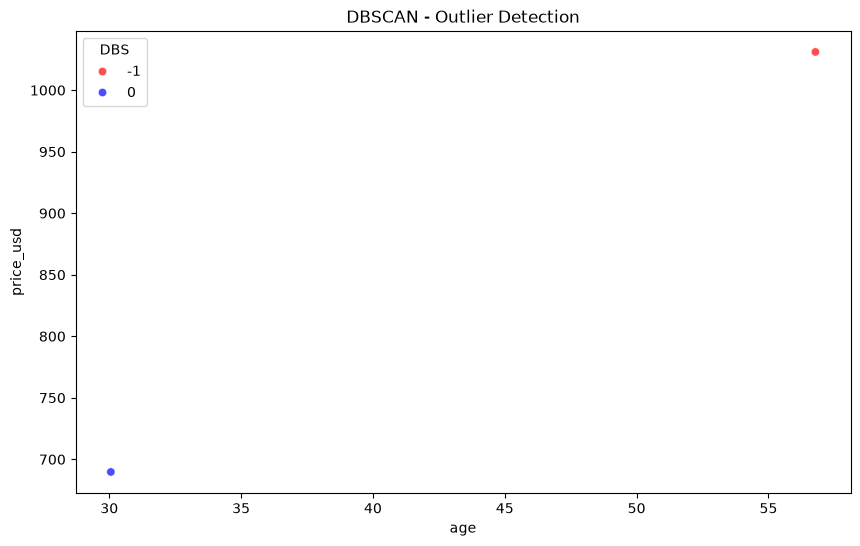

In [37]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=Kmeansdata.groupby("DBS").mean().round(2),
    x="age",
    y="price_usd",
    hue="DBS",
    palette={0:"blue",-1:"red"},
    alpha=0.7
)

plt.title("DBSCAN - Outlier Detection")
plt.show()

In [38]:
from sklearn.decomposition import PCA

In [39]:
pca = PCA(n_components=4)

In [40]:
pca_data = pca.fit_transform(scaleddata)

In [41]:
print(pca.explained_variance_ratio_)

[0.39728352 0.25058488 0.2493689  0.1027627 ]


In [42]:
type(pca)

sklearn.decomposition._pca.PCA

In [43]:
pca_data.shape

(50000, 4)

In [44]:
pca_df = pd.DataFrame(pca_data,columns=['PC1','PC2','PC3','PC4'])

In [45]:
display(pca_df.head())

,PC1,PC2,PC3,PC4
0,-1.782094,0.357838,2.024972,-0.009166
1,-0.260313,-1.845312,-0.089730,-0.519350
2,1.345218,0.155210,-0.656763,1.053506
3,-0.774324,-0.916958,-0.813500,1.054741
4,0.313613,0.855565,0.398648,-0.003251


Text(0.5, 0, 'PC3')

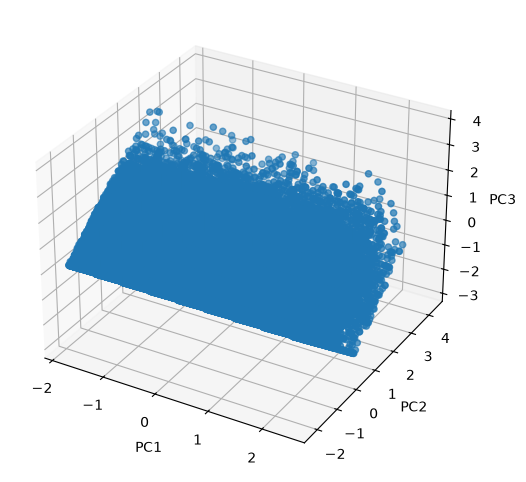

In [46]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,6))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    pca_df['PC3']
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')


In [47]:
print(dir(pca))

['__abstractmethods__', '__annotations__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__str__', '__subclasshook__', '__weakref__', '_abc_impl', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_fit', '_fit_full', '_fit_svd_solver', '_fit_truncated', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_n_features_out', '_parameter_constraints', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_transform', '_validate_params', 'components_', 'copy', 'explained_variance_', 'explained_var

In [48]:
import sklearn
print(sklearn.__version__)

1.9.1


In [49]:
print(pca.__dict__)

{'n_components': 4, 'copy': True, 'whiten': False, 'svd_solver': 'auto', 'tol': 0.0, 'iterated_power': 'auto', 'n_oversamples': 10, 'power_iteration_normalizer': 'auto', 'random_state': None, 'n_features_in_': 4, '_fit_svd_solver': 'covariance_eigh', 'mean_': array([-1.85735871e-16,  5.65592018e-17,  6.25277607e-18,  1.30384592e-16]), 'noise_variance_': 0.0, 'n_samples_': 50000, 'n_components_': 4, 'components_': array([[ 1.72003004e-02,  6.08695578e-03,  7.06962928e-01,
         7.07015217e-01],
       [ 6.96580769e-01,  7.17285735e-01, -1.36912896e-02,
        -9.43155212e-03],
       [ 7.17259419e-01, -6.96752554e-01, -7.87468004e-03,
        -3.57682351e-03],
       [-4.27862117e-03, -4.32928056e-05, -7.07074223e-01,
         7.07126393e-01]]), 'explained_variance_': array([1.58916586, 1.00235956, 0.99749555, 0.41105903]), 'explained_variance_ratio_': array([0.39728352, 0.25058488, 0.2493689 , 0.1027627 ]), 'singular_values_': array([281.8806553 , 223.86821065, 223.32438316, 143.36

In [50]:
mob_rev.head(5)

,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,27996.73,INR,83.00,2.0,...,Hindi,11/6/2023,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,1754.35,BRL,5.70,4.0,...,Portuguese,3/30/2023,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,71755.99,INR,83.00,4.0,...,Hindi,12/7/2022,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,2425.65,AED,3.67,3.0,...,English,3/11/2025,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,4515.14,BRL,5.70,3.0,...,Portuguese,9/29/2023,True,3,3,2,2,1,0,BestBuy


In [51]:
mfactorize = mob_rev[["review_id","customer_name","performance_rating"]].iloc[0:5000,:]

In [52]:
pivotted = mfactorize.pivot(index="customer_name",columns="review_id",values="performance_rating")

In [53]:
pivottedfillna = pivotted.fillna(0)

In [54]:
from sklearn.decomposition import TruncatedSVD

In [55]:
svd = TruncatedSVD(n_components=5,random_state=42)

In [56]:
cust_pred = svd.fit_transform(pivottedfillna)

In [57]:
cust_pred.shape

(4949, 5)

In [58]:
svd.components_

array([[ 2.56499243e-06,  7.33518486e-05,  1.00999559e-05, ...,
        -5.21284020e-04,  2.23824996e-05,  3.51565030e-05],
       [ 2.10712435e-05, -5.17785347e-04, -1.31524046e-05, ...,
         6.27825277e-04, -8.36244516e-05, -5.24306939e-04],
       [ 4.51696020e-05,  3.41123493e-04, -2.01060811e-05, ...,
        -1.25335876e-03, -1.75050193e-04, -3.41137697e-03],
       [-2.03954513e-04, -3.09775138e-04,  8.64049877e-06, ...,
        -3.27493830e-03,  5.94942591e-05, -6.36047903e-05],
       [ 1.28211675e-04, -5.73765690e-04, -2.74837787e-05, ...,
        -5.44686588e-04, -1.99464406e-05,  3.28477092e-03]],
      shape=(5, 5000))

In [59]:
import numpy as np

In [60]:
predicted_ratings = np.dot(
    cust_pred,
    svd.components_
)

In [61]:
predicted_ratings.shape

(4949, 5000)

In [62]:
pred_df = pd.DataFrame(
    predicted_ratings,
    index=pivotted.index,
    columns=pivotted.columns
)

In [63]:
pred_df.head()

review_id,1,2,3,4,5,6,7,8,9,10,...,4991,4992,4993,4994,4995,4996,4997,4998,4999,5000
customer_name,,,,,,,,,,,,,,,,,,,,,
Aadhya Thaker,-4.166711e-07,-5.869458e-06,9.046362e-08,6.657285e-09,1.192613e-08,1.264278e-04,7.665123e-09,1.059251e-08,-2.609336e-09,9.821823e-07,...,-5.144818e-13,-1.460180e-07,-2.211667e-05,-2.045250e-04,-1.901290e-06,5.324628e-12,-7.633937e-12,-9.556044e-06,1.998608e-06,5.400955e-05
Aadi Ben,-9.689618e-08,-2.250465e-08,3.427827e-09,1.024560e-09,9.415578e-10,-4.630430e-07,1.978796e-10,-5.630724e-10,1.606768e-10,2.041683e-08,...,-1.241650e-13,9.821435e-09,-3.807549e-07,9.009352e-06,-3.874105e-08,-9.265242e-14,2.910978e-13,-1.431533e-06,2.926579e-09,-8.769837e-07
Aarini Babu,-7.579166e-10,3.106514e-09,2.108693e-10,2.481218e-12,2.657628e-12,2.676932e-07,5.436965e-12,-1.575160e-11,3.123443e-12,-9.493186e-10,...,2.413636e-15,-3.792518e-11,2.908603e-08,6.232699e-08,1.338638e-09,1.012969e-15,-4.222304e-15,9.828464e-09,4.574112e-10,-1.359595e-08
Aarini Suresh,-8.997691e-08,-4.723922e-06,-1.504753e-07,7.132028e-09,6.883434e-09,-1.677703e-04,-3.353062e-09,1.235865e-08,-4.963877e-09,1.132711e-06,...,-2.651068e-12,-8.648895e-08,-2.719767e-05,-9.050930e-06,-1.641854e-06,-2.400030e-13,3.191847e-12,-1.714852e-05,-7.882716e-08,1.508876e-05
Aarnav Dhaliwal,-9.683789e-14,-3.402306e-13,8.306197e-15,1.191430e-15,1.182950e-15,1.742603e-11,1.936168e-16,-1.241021e-16,-5.830853e-16,3.158885e-14,...,-1.548226e-21,-3.605230e-14,3.786627e-13,3.115196e-12,-4.320170e-14,1.770756e-19,-3.585002e-19,-6.503524e-13,6.167858e-14,8.029542e-13


In [64]:
perf_rating = pivotted.loc['Aadhya Thaker'].dropna().index

In [65]:
perf_rating

Index([4518], dtype='int64', name='review_id')

In [66]:
recommend = pred_df.loc['Aadhya Thaker']

In [67]:
recommend = recommend.drop(perf_rating)

In [68]:
recommend.sort_values(ascending=False).head(5)

review_id
2024    0.003109
2579    0.001865
1462    0.001636
22      0.001411
466     0.001411
Name: Aadhya Thaker, dtype: float64

In [69]:
ALSDS = mob_rev[mob_rev['customer_name'] == 'Aaron Johnson']

In [70]:
ALSDSF = ALSDS[["review_id","customer_name","brand","model","rating"]]

In [71]:
ALSDSF

,review_id,customer_name,brand,model,rating
3690,3691,Aaron Johnson,Motorola,Razr 40,2.0
10186,10187,Aaron Johnson,Realme,Realme Narzo 70,5.0
24503,24504,Aaron Johnson,Xiaomi,Redmi Note 13,1.0
26546,26547,Aaron Johnson,Apple,iPhone SE,4.0
27501,27502,Aaron Johnson,Apple,iPhone 14,3.0
32423,32424,Aaron Johnson,Google,Pixel 8,3.0
37879,37880,Aaron Johnson,Realme,Realme Narzo 70,1.0


In [72]:
from pyspark.sql import SparkSession

In [73]:
spark = SparkSession.builder \
    .appName("ALS_Demo") \
    .getOrCreate()

c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [74]:
ratings = spark.createDataFrame(ALSDSF)

c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [75]:
ratings.show(5)

+---------+-------------+--------+---------------+------+
|review_id|customer_name|   brand|          model|rating|
+---------+-------------+--------+---------------+------+
|     3691|Aaron Johnson|Motorola|        Razr 40|   2.0|
|    10187|Aaron Johnson|  Realme|Realme Narzo 70|   5.0|
|    24504|Aaron Johnson|  Xiaomi|  Redmi Note 13|   1.0|
|    26547|Aaron Johnson|   Apple|      iPhone SE|   4.0|
|    27502|Aaron Johnson|   Apple|      iPhone 14|   3.0|
+---------+-------------+--------+---------------+------+
only showing top 5 rows


In [76]:
from pyspark.ml.feature import StringIndexer

user_indexer = StringIndexer(
    inputCol="customer_name",
    outputCol="userId"
)

item_indexer = StringIndexer(
    inputCol="review_id",
    outputCol="itemId"
)

ratings = user_indexer.fit(ratings).transform(ratings)
ratings = item_indexer.fit(ratings).transform(ratings)

ratings.show(5)

+---------+-------------+--------+---------------+------+------+------+
|review_id|customer_name|   brand|          model|rating|userId|itemId|
+---------+-------------+--------+---------------+------+------+------+
|     3691|Aaron Johnson|Motorola|        Razr 40|   2.0|   0.0|   5.0|
|    10187|Aaron Johnson|  Realme|Realme Narzo 70|   5.0|   0.0|   0.0|
|    24504|Aaron Johnson|  Xiaomi|  Redmi Note 13|   1.0|   0.0|   1.0|
|    26547|Aaron Johnson|   Apple|      iPhone SE|   4.0|   0.0|   2.0|
|    27502|Aaron Johnson|   Apple|      iPhone 14|   3.0|   0.0|   3.0|
+---------+-------------+--------+---------------+------+------+------+
only showing top 5 rows


In [77]:
from pyspark.ml.recommendation import ALS

als = ALS(
    userCol="userId",
    itemCol="itemId",
    ratingCol="rating",
    rank=5,
    maxIter=10,
    regParam=0.1,
    coldStartStrategy="drop"
)

als_model = als.fit(ratings)

In [78]:
als_model.userFactors.show(5, truncate=False)

+---+------------------------------------------------------------+
|id |features                                                    |
+---+------------------------------------------------------------+
|0  |[0.12175889, 0.4083327, -0.39599472, -0.7021432, -1.2104657]|
+---+------------------------------------------------------------+



In [79]:
als_model.itemFactors.show(5, truncate=False)

+---+---------------------------------------------------------------+
|id |features                                                       |
+---+---------------------------------------------------------------+
|0  |[0.25835758, 0.86643237, -0.8402527, -1.4898626, -2.5684612]   |
|1  |[0.051671516, 0.17328648, -0.16805054, -0.2979725, -0.51369226]|
|2  |[0.20668606, 0.69314593, -0.67220217, -1.19189, -2.054769]     |
|3  |[0.15501456, 0.51985943, -0.50415164, -0.89391756, -1.5410768] |
|4  |[0.15501456, 0.51985943, -0.50415164, -0.89391756, -1.5410768] |
+---+---------------------------------------------------------------+
only showing top 5 rows


In [80]:
recommendations = als_model.recommendForAllUsers(5)

recommendations.show(truncate=False)

+------+----------------------------------------------------------------------------+
|userId|recommendations                                                             |
+------+----------------------------------------------------------------------------+
|0     |[{0, 4.8731165}, {2, 3.8984933}, {4, 2.92387}, {3, 2.92387}, {5, 1.9492466}]|
+------+----------------------------------------------------------------------------+



In [81]:
recommendations.toPandas()

c:\Users\Nanda\AppData\Local\Programs\Python\Python312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,userId,recommendations
0,0,"[{'itemId': 0, 'rating': 4.873116493225098}, {..."
